# RPG GAME / 미니과제│머신러닝 복습 과제 — 선형회귀

## 공통 실습 데이터

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 게임 플레이 기록 20개
df = pd.DataFrame({
    "play_hours": [1, 2, 3, 4, 5, 1, 2, 3, 4, 5, 2, 4, 1, 5, 3, 2, 5, 4, 3, 1],
    "quests": [2, 3, 5, 6, 8, 4, 2, 6, 5, 7, 5, 8, 1, 6, 4, 3, 9, 7, 7, 3],
    "monsters": [10, 25, 30, 45, 60, 18, 35, 40, 55, 70, 20, 50, 15, 80, 25, 45, 65, 35, 55, 28],
    "xp": [410, 680, 965, 1240, 1620, 565, 755, 1100, 1280, 1660, 755, 1415, 395, 1690, 870, 885, 1700, 1210, 1290, 635],
})

df

,play_hours,quests,monsters,xp
0,1,2,10,410
1,2,3,25,680
2,3,5,30,965
3,4,6,45,1240
4,5,8,60,1620
5,1,4,18,565
6,2,2,35,755
7,3,6,40,1100
8,4,5,55,1280
9,5,7,70,1660


## 단순 선형회귀 — 플레이 시간으로 경험치 예측

In [3]:
from sklearn.linear_model import LinearRegression

# 입력 특성과 정답 분리
X = df[["play_hours"]]
y = df["xp"]

# 모델 학습
simple_model = LinearRegression()
simple_model.fit(X, y)

print(f"기울기: {simple_model.coef_[0]:.2f}")
print(f"절편: {simple_model.intercept_:.2f}")

# 새로운 데이터 예측
new_player = pd.DataFrame({"play_hours": [3]})
print(f"예상 경험치: {simple_model.predict(new_player)[0]:.2f} XP")

기울기: 285.00
절편: 201.00
예상 경험치: 1056.00 XP


## 다중 선형회귀 — 세 가지 특성으로 예측

In [6]:
features = ["play_hours", "quests", "monsters"]
X = df[features]
y = df["xp"]
print("X shape:", X.shape)

# 다중 선형회귀 모델 학습
multiple_model = LinearRegression()
multiple_model.fit(X, y)

# 특성별 가중치와 절편 확인
for feature, weight in zip(features, multiple_model.coef_):
    print(f"{feature}: {weight:.2f}")
print(f"절편: {multiple_model.intercept_:.2f}")

new_player = pd.DataFrame({
    "play_hours": [3], "quests": [5], "monsters": [40]
})
print(f"예상 경험치: {multiple_model.predict(new_player)[0]:.2f} XP")

X shape: (20, 3)
play_hours: 107.81
quests: 51.10
monsters: 9.36
절편: 97.41
예상 경험치: 1050.64 XP


## 모델 평가 — 단순 회귀와 다중 회귀 비교

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[features]
y = df["xp"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 같은 학습·테스트 샘플로 두 모델 비교
simple_model = LinearRegression()
simple_model.fit(X_train[["play_hours"]], y_train)
simple_pred = simple_model.predict(X_test[["play_hours"]])

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)

for name, pred in [("단순 회귀", simple_pred), ("다중 회귀", multiple_pred)]:
    print(name)
    print(f"MAE: {mean_absolute_error(y_test, pred):.2f}")
    print(f"MSE: {mean_squared_error(y_test, pred):.2f}")
    print(f"R2: {r2_score(y_test, pred):.4f}")

# 테스트 MSE 비교
if mean_squared_error(y_test, multiple_pred) < mean_squared_error(y_test, simple_pred):
    print("다중 회귀 모델의 테스트 MSE가 더 작습니다.")
else:
    print("단순 회귀 모델의 데스트 MSE가 더 작거나 같습니다.")

단순 회귀
MAE: 104.32
MSE: 11450.96
R2: 0.8918
다중 회귀
MAE: 13.28
MSE: 255.66
R2: 0.9976
다중 회귀 모델의 테스트 MSE가 더 작습니다.


## 특성 스케일링 — StandardScaler

In [9]:
from sklearn.preprocessing import StandardScaler

# 학습 데이터만으로 표준화 기준 개선
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 데이터프레임 변환
scaled_df = pd.DataFrame(X_train_scaled, columns=features)

print("평균")
print(scaled_df.mean().round(4).to_string())
print("표준편차")
print(scaled_df.std(ddof=0).round(4).to_string())
print("처음 5행:")
print(scaled_df.head().round(4).to_string(index=False))

평균
play_hours   -0.0
quests       -0.0
monsters      0.0
표준편차
play_hours    1.0
quests        1.0
monsters      1.0
처음 5행:
 play_hours  quests  monsters
    -1.4667 -0.6320   -1.2418
     0.5959  1.1738    0.3868
     0.5959  0.2709    0.1323
    -0.0917  0.7223    0.6412
     1.2834  1.6252    1.1502


## 경사하강법 — SGDRegressor 학습 과정 관찰

첫 번째 학습 MSE: 988559.48
마지막 학습 MSE: 82.32


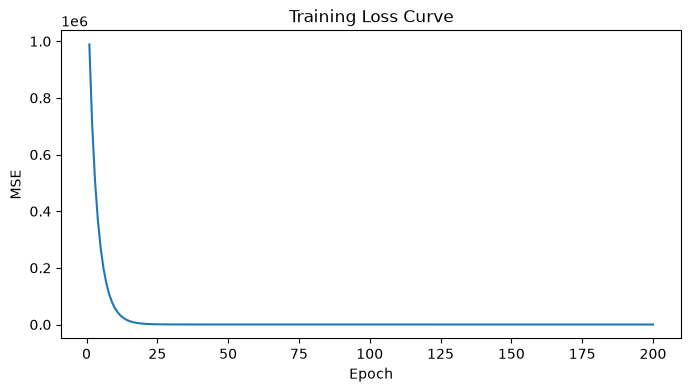

최종 테스트 MSE: 256.93


In [10]:
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(
    loss="squared_error",
    penalty=None,
    learning_rate="constant",
    eta0=0.01,
    random_state=42
)

losses = []
for epoch in range(200):
    # 한 Epoch 학습
    sgd.partial_fit(X_train_scaled, y_train)
    # 학습 데이터 예측 및 MSE 저장
    pred = sgd.predict(X_train_scaled)
    losses.append(mean_squared_error(y_train, pred))

print(f"첫 번째 학습 MSE: {losses[0]:.2f}")
print(f"마지막 학습 MSE: {losses[-1]:.2f}")

# 손실 곡선 시각화
plt.figure(figsize=(8, 4))
plt.plot(range(1, 201), losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training Loss Curve")
plt.show()

# 최종 테스트 데이터 평가
test_pred = sgd.predict(X_test_scaled)
print(f"최종 테스트 MSE: {mean_squared_error(y_test, test_pred):.2f}")